# Crop Type Classification with Sentinel-2 Imagery

This notebook builds a machine learning pipeline that classifies crop type for field plots in the Luís Eduardo Magalhães (LEM) region of western Bahia, Brazil. It combines the LEM+ ground-truth dataset from Embrapa with Sentinel-2 imagery.

## 1. Load the LEM+ dataset

LEM+ provides one polygon per field and one land-use label per month, from October 2019 to September 2020. See `data/README.md` for how to download it.

In [1]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

SHAPEFILE = Path("data/raw/LEM_dataset.shp")
MONTHS = [
    "Oct_2019", "Nov_2019", "Dec_2019", "Jan_2020", "Feb_2020", "Mar_2020",
    "Apr_2020", "May_2020", "Jun_2020", "Jul_2020", "Aug_2020", "Sep_2020",
]

fields = gpd.read_file(SHAPEFILE)
print(f"{len(fields)} fields, CRS: {fields.crs}")
fields.head()

1854 fields, CRS: EPSG:4326


,id,Oct_2019,Nov_2019,Dec_2019,Jan_2020,Feb_2020,Mar_2020,Apr_2020,May_2020,Jun_2020,Jul_2020,Aug_2020,Sep_2020,Note,geometry
0,0,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Conversion area,Conversion area,Conversion area,Conversion area,Conversion area,Conversion area,Conversion area,NaN,"POLYGON ((-45.82294 -12.14292, -45.8228 -12.14..."
1,1,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,Cerrado,NaN,"POLYGON ((-45.82389 -12.14325, -45.8176 -12.14..."
2,2,Pasture,Pasture,Pasture,Pasture,Pasture,Pasture,Pasture,Pasture,Pasture,Pasture,Pasture,Pasture,NaN,"POLYGON ((-45.82461 -12.14622, -45.81824 -12.1..."
3,3,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,NaN,"POLYGON ((-45.81202 -12.14691, -45.81194 -12.1..."
4,4,Not identified,Uncultivated soil,Uncultivated soil,Uncultivated soil,Soybean,Soybean,Soybean,Uncultivated soil,Uncultivated soil,Uncultivated soil,Uncultivated soil,Uncultivated soil,NaN,"POLYGON ((-45.83022 -12.15034, -45.83024 -12.1..."


### Validate the polygons

The rest of the pipeline depends on one valid polygon per field, so these checks stop the notebook if that does not hold. Areas are computed in a projected UTM CRS, because degrees cannot be used to measure area.

In [2]:
assert fields["id"].is_unique, "Field ids must be unique"
assert fields[MONTHS].notna().all().all(), "Every field needs a label for every month"

print("Missing geometries:", int(fields.geometry.isna().sum()))
print("Invalid geometries:", int((~fields.geometry.is_valid).sum()))

utm_crs = fields.estimate_utm_crs()
fields["area_ha"] = fields.to_crs(utm_crs).area / 10_000
print("Projected CRS:", utm_crs.name)
fields["area_ha"].describe().round(1)

Missing geometries: 0
Invalid geometries: 0
Projected CRS: WGS 84 / UTM zone 23S


count    1854.0
mean      135.3
std       135.8
min         0.1
25%        50.6
50%       101.7
75%       181.7
max      2620.5
Name: area_ha, dtype: float64

### Reshape the labels

The shapefile stores one column per month. A long table, with one row per field and month, is the format needed to join the labels with the Sentinel-2 time series later.

In [3]:
labels = fields.melt(
    id_vars="id", value_vars=MONTHS, var_name="month", value_name="label"
)
labels["month"] = pd.to_datetime(labels["month"], format="%b_%Y")

print(f"{len(labels)} field-month rows, {labels['label'].nunique()} classes")
labels.head()

22248 field-month rows, 16 classes


,id,month,label
0,0,2019-10-01,Cerrado
1,1,2019-10-01,Cerrado
2,2,2019-10-01,Pasture
3,3,2019-10-01,Coffee
4,4,2019-10-01,Not identified


In [4]:
class_by_month = (
    labels.pivot_table(index="label", columns="month", aggfunc="size", fill_value=0)
    .rename(columns=lambda month: month.strftime("%b %Y"))
)
class_by_month.loc[class_by_month.sum(axis=1).sort_values(ascending=False).index]

month,Oct 2019,Nov 2019,Dec 2019,Jan 2020,Feb 2020,Mar 2020,Apr 2020,May 2020,Jun 2020,Jul 2020,Aug 2020,Sep 2020
label,,,,,,,,,,,,
Uncultivated soil,1433,1463,1307,162,38,477,1061,949,420,480,669,1137
Soybean,0,4,126,1133,1173,712,111,4,1,1,0,0
Cerrado,161,161,159,158,157,151,149,147,144,139,138,137
Millet,0,4,5,4,5,5,8,106,406,422,332,64
Pasture,95,95,95,95,95,97,97,102,102,102,102,102
Corn,0,0,66,158,168,175,181,184,131,56,36,13
Brachiaria,6,6,7,7,7,7,11,53,207,249,250,222
Cotton,0,0,1,48,121,138,138,138,137,118,71,16
Sorghum,0,0,0,1,3,3,7,51,161,163,147,60


### How often does a field change class?

A field can hold several land uses within one season, for example soybean in summer followed by millet in winter. This matters when defining the prediction target, because a single label per season has to be derived from the monthly labels.

In [5]:
classes_per_field = fields[MONTHS].nunique(axis=1)
classes_per_field.value_counts().sort_index().rename_axis("classes in season").rename("fields")

classes in season
1    313
2    559
3    929
4     53
Name: fields, dtype: int64

## 2. Extract Sentinel-2 composites with Google Earth Engine

The labels are monthly, so the imagery is aggregated to the same resolution: one composite per month, from October 2019 to September 2020.

For each month, the pipeline:

1. Selects Sentinel-2 L2A surface reflectance images over the study area
2. Masks clouds, cloud shadows and cirrus with the Scene Classification Layer (SCL)
3. Takes the per-pixel median of the clear observations
4. Computes NDVI, EVI and NDWI from the composite
5. Averages the pixels inside each field polygon

The resulting table is stored in `data/sentinel2_features.csv`, so the rest of the notebook runs without an Earth Engine account. To rebuild it, delete the CSV, replace `EE_PROJECT` with your own Cloud project and run `earthengine authenticate` once.

In [6]:
import ee

EE_PROJECT = "crop-classification-sentinel2"
FEATURES_CSV = Path("data/sentinel2_features.csv")

COLLECTION = "COPERNICUS/S2_SR_HARMONIZED"
BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]
INDICES = ["NDVI", "EVI", "NDWI"]
CLEAR_SCL_CLASSES = [4, 5, 6, 7]  # vegetation, bare soil, water, unclassified
SCALE_METERS = 20  # native resolution of the SWIR bands
CHUNK_SIZE = 400  # fields per request, to stay within Earth Engine limits

needs_extraction = not FEATURES_CSV.exists()
if needs_extraction:
    ee.Initialize(project=EE_PROJECT)
    study_area = ee.Geometry.Rectangle([float(value) for value in fields.total_bounds])

In [7]:
def mask_clouds(image):
    """Keep clear pixels and convert the bands to surface reflectance."""
    scl = image.select("SCL")
    clear = ee.Image(0)
    for scl_class in CLEAR_SCL_CLASSES:
        clear = clear.Or(scl.eq(scl_class))
    return image.select(BANDS).divide(10_000).updateMask(clear)


def monthly_composite(month_start):
    """Build a cloud-free median composite with vegetation indices for one month."""
    start = ee.Date(month_start)
    images = (
        ee.ImageCollection(COLLECTION)
        .filterBounds(study_area)
        .filterDate(start, start.advance(1, "month"))
        .map(mask_clouds)
    )
    composite = images.median()
    ndvi = composite.normalizedDifference(["B8", "B4"]).rename("NDVI")
    ndwi = composite.normalizedDifference(["B3", "B8"]).rename("NDWI")
    evi = composite.expression(
        "2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1)",
        {
            "NIR": composite.select("B8"),
            "RED": composite.select("B4"),
            "BLUE": composite.select("B2"),
        },
    ).rename("EVI")
    # clear_obs counts how many cloud-free images contributed to each pixel
    clear_obs = images.select("B4").count().rename("clear_obs")
    return composite.addBands([ndvi, evi, ndwi, clear_obs])


def extract_month(month_start, polygons):
    """Return the mean band and index values per field for one month."""
    composite = monthly_composite(month_start)
    rows = []
    for offset in range(0, len(polygons), CHUNK_SIZE):
        chunk = polygons.iloc[offset : offset + CHUNK_SIZE][["id", "geometry"]]
        result = composite.reduceRegions(
            collection=ee.FeatureCollection(chunk.__geo_interface__),
            reducer=ee.Reducer.mean(),
            scale=SCALE_METERS,
            tileScale=4,
        ).getInfo()
        rows += [feature["properties"] for feature in result["features"]]
    table = pd.DataFrame(rows)
    table.insert(1, "month", pd.Timestamp(month_start))
    return table

### Build the feature table

This produces one row per field and month, with the band and index values plus that month's label. The extraction runs month by month and is skipped when the CSV already exists.

In [8]:
FEATURE_COLUMNS = BANDS + INDICES + ["clear_obs"]

if needs_extraction:
    months = pd.date_range("2019-10-01", periods=len(MONTHS), freq="MS")
    monthly_tables = []
    for month in months:
        monthly_tables.append(extract_month(month.strftime("%Y-%m-%d"), fields))
        print(f"{month:%b %Y}: {len(monthly_tables[-1])} fields")

    extracted = pd.concat(monthly_tables, ignore_index=True)
    extracted[FEATURE_COLUMNS] = extracted[FEATURE_COLUMNS].round(5)
    features = extracted.merge(labels, on=["id", "month"], how="left", validate="one_to_one")
    features = features[["id", "month", "label"] + FEATURE_COLUMNS]
    features.sort_values(["id", "month"]).to_csv(FEATURES_CSV, index=False)

features = pd.read_csv(FEATURES_CSV, dtype={"id": str}, parse_dates=["month"])
print(f"{len(features)} rows, {features['id'].nunique()} fields, {features['month'].nunique()} months")
features.head()

22248 rows, 1854 fields, 12 months


,id,month,label,B2,B3,B4,B8,B11,B12,NDVI,EVI,NDWI,clear_obs
0,0,2019-10-01,Cerrado,0.06072,0.08878,0.11190,0.25635,0.32264,0.21751,0.39272,0.24535,-0.48616,5.00000
1,0,2019-11-01,Cerrado,0.05885,0.08958,0.09870,0.25522,0.31051,0.20294,0.44289,0.27854,-0.48072,2.00000
2,0,2019-12-01,Cerrado,0.04779,0.07765,0.06973,0.26892,0.26428,0.16247,0.58870,0.37522,-0.55180,3.23512
3,0,2020-01-01,Cerrado,0.06890,0.09175,0.07799,0.29829,0.25986,0.15095,0.58649,0.44027,-0.52957,2.96361
4,0,2020-02-01,Cerrado,0.12118,0.13713,0.12480,0.29330,0.23407,0.15318,0.42773,0.37341,-0.38002,1.33234


### Check the data quality

Every field and month should be present, with physically plausible values. Rainy months are the main risk, because a field with no clear observation has no values at all. `clear_obs` shows how many cloud-free images support each monthly value.

In [9]:
assert len(features) == len(fields) * len(MONTHS), "Expected one row per field and month"
assert features["label"].notna().all(), "Every row needs a label"
assert features[["NDVI", "NDWI"]].stack().between(-1, 1).all(), "Normalized indices must be between -1 and 1"
assert features[BANDS].stack().ge(0).all(), "Reflectance cannot be negative"

quality = features.groupby("month").agg(
    missing_ndvi=("NDVI", lambda values: int(values.isna().sum())),
    median_clear_obs=("clear_obs", "median"),
    min_clear_obs=("clear_obs", "min"),
    median_ndvi=("NDVI", "median"),
).round(2)
quality.index = quality.index.strftime("%b %Y")
quality

,missing_ndvi,median_clear_obs,min_clear_obs,median_ndvi
month,,,,
Oct 2019,0,5.00,2.95,0.17
Nov 2019,0,3.04,1.00,0.20
Dec 2019,0,3.74,1.79,0.26
Jan 2020,0,3.16,1.25,0.76
Feb 2020,0,2.42,1.00,0.77
Mar 2020,0,2.00,1.00,0.50
Apr 2020,0,2.48,1.00,0.27
May 2020,0,3.00,1.01,0.45
Jun 2020,0,5.55,3.07,0.52


## 3. Exploratory analysis

February 2020 is used as the reference month here, because it is when the most fields hold a summer crop. The main classes get their own color and the remaining ones are grouped as "Other".

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
CLASS_COLORS = {
    "Soybean": "#2a78d6",
    "Corn": "#eb6834",
    "Cotton": "#1baf7a",
    "Cerrado": "#eda100",
    "Pasture": "#e87ba4",
}
OTHER_COLOR = "#b5b3ad"
REFERENCE_MONTH = "Feb_2020"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
})

fields["group"] = fields[REFERENCE_MONTH].where(fields[REFERENCE_MONTH].isin(CLASS_COLORS), "Other")

### Where are the fields?

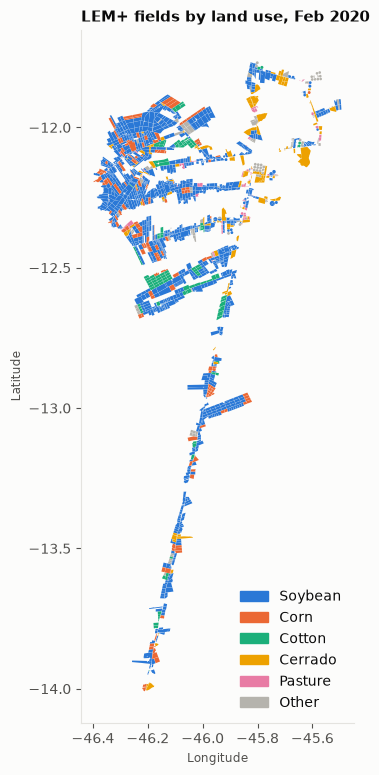

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 9))
fields[fields["group"] == "Other"].plot(ax=ax, color=OTHER_COLOR, linewidth=0)
for name, color in CLASS_COLORS.items():
    fields[fields["group"] == name].plot(ax=ax, color=color, linewidth=0)

ax.set_title(f"LEM+ fields by land use, {REFERENCE_MONTH.replace('_', ' ')}", loc="left")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(
    handles=[Patch(color=color, label=name) for name, color in CLASS_COLORS.items()]
    + [Patch(color=OTHER_COLOR, label="Other")],
    loc="lower right", frameon=False,
)
plt.show()

### How balanced are the classes?

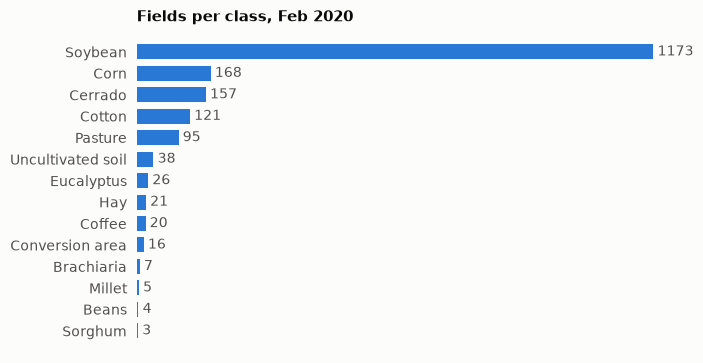

In [12]:
counts = fields[REFERENCE_MONTH].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.barh(counts.index, counts.values, color=CLASS_COLORS["Soybean"], height=0.7)
ax.bar_label(bars, padding=3, color=MUTED)
ax.set_title(f"Fields per class, {REFERENCE_MONTH.replace('_', ' ')}", loc="left")
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(left=False)
plt.show()

The classes are heavily imbalanced: soybean holds 1,173 of the 1,854 fields (63%), and some classes have fewer than 10. A model that always predicts soybean would already reach high accuracy, so F1-macro, which weights every class equally, is the more informative metric.

### NDVI curves per class

Each panel shows the median NDVI of the fields in that class, with the shaded band covering the 25th to 75th percentiles. Fields are grouped by their February label, so a curve also shows what those fields did before and after that month.

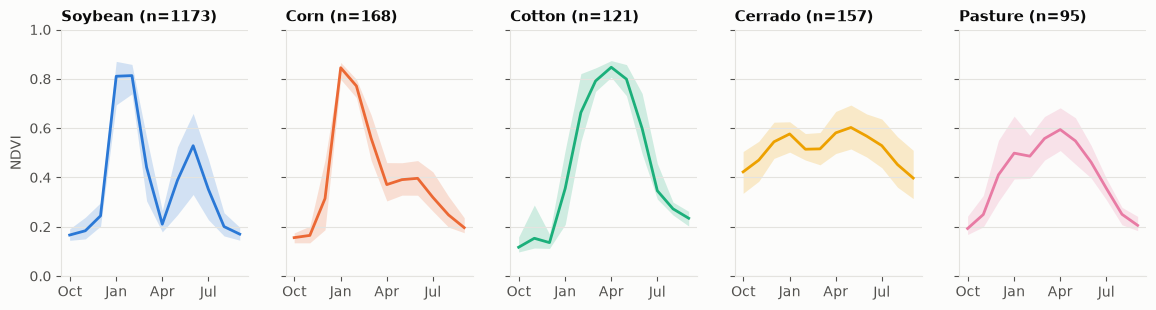

In [13]:
with_group = features.merge(fields[["id", "group"]], on="id")
ndvi_stats = (
    with_group[with_group["group"].isin(CLASS_COLORS)]
    .groupby(["group", "month"])["NDVI"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
)

fig, axes = plt.subplots(1, len(CLASS_COLORS), figsize=(14, 3.2), sharey=True)
for ax, (name, color) in zip(axes, CLASS_COLORS.items()):
    stats = ndvi_stats.loc[name]
    ax.fill_between(stats.index, stats[0.25], stats[0.75], color=color, alpha=0.2, linewidth=0)
    ax.plot(stats.index, stats[0.5], color=color, linewidth=2)
    ax.set_title(f"{name} (n={int((fields['group'] == name).sum())})", loc="left")
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_xticks(stats.index[::3], [month.strftime("%b") for month in stats.index[::3]])
axes[0].set_ylabel("NDVI")
axes[0].set_ylim(0, 1)
plt.show()

The curves show why time series help:

- **Soybean** peaks at about 0.8 in January and February and drops sharply by April. A second, smaller rise in June matches the second-season crops in the labels, such as millet and brachiaria.
- **Corn** starts like soybean, which makes this the hardest pair to separate in January, but it declines more slowly and has no clear second peak.
- **Cotton** is later than both, peaking around April.
- **Cerrado** stays between 0.4 and 0.6 all year, while **pasture** follows the rainy season with a lower peak.

The differences appear after the peak, so the months from March to June should carry much of the information.

### Do low-observation months carry residual haze?

Some rainy-season composites rest on a single clear image. Thin haze raises the blue band, so comparing blue reflectance across levels of `clear_obs` shows whether those composites are contaminated. Only soybean fields in the rainy months are compared, to keep land cover constant.

In [14]:
rainy = with_group[
    (with_group["group"] == "Soybean")
    & (with_group["label"] == "Soybean")
    & with_group["month"].isin(pd.to_datetime(["2020-01-01", "2020-02-01"]))
].copy()
rainy["clear_obs_level"] = pd.cut(
    rainy["clear_obs"], bins=[0, 1.5, 2.5, 4, 20], labels=["up to 1.5", "1.5 to 2.5", "2.5 to 4", "over 4"]
)
rainy.groupby("clear_obs_level", observed=True).agg(
    field_months=("id", "size"),
    median_blue=("B2", "median"),
    p90_blue=("B2", lambda values: values.quantile(0.9)),
    median_ndvi=("NDVI", "median"),
).round(3)

,field_months,median_blue,p90_blue,median_ndvi
clear_obs_level,,,,
up to 1.5,110,0.059,0.112,0.809
1.5 to 2.5,682,0.065,0.102,0.796
2.5 to 4,1256,0.047,0.079,0.832
over 4,238,0.052,0.085,0.782


The effect is small. Below 2.5 clear observations, the 90th percentile of blue reflectance rises from about 0.08 to 0.10–0.11, so a minority of composites do carry some haze. Median NDVI stays between 0.78 and 0.83 across all levels, which suggests NDVI is robust to it, so no rows are removed. The blue band should be read with more caution in January and February.

## 4. Build the modeling dataset

### Define one label per field

Monthly labels change during the season, so the model needs a single target per field. This project predicts the **main summer land use**, using these rules:

- Use the February label, the month when the most fields hold a summer crop
- If a field is already harvested in February (`Uncultivated soil`), use its January label
- Drop fields that are still `Uncultivated soil`, plus `Not identified` and `Conversion area`, because these do not describe a crop or a stable land cover
- Group classes with too few fields to evaluate as `Other crops`

In [15]:
EXCLUDED_CLASSES = ["Uncultivated soil", "Not identified", "Conversion area"]
MIN_FIELDS_PER_CLASS = 15

season_label = fields["Feb_2020"].where(fields["Feb_2020"] != "Uncultivated soil", fields["Jan_2020"])
season_label.index = fields["id"]
season_label = season_label[~season_label.isin(EXCLUDED_CLASSES)]

class_sizes = season_label.value_counts()
rare_classes = class_sizes[class_sizes < MIN_FIELDS_PER_CLASS].index
season_label = season_label.replace(dict.fromkeys(rare_classes, "Other crops"))

print(f"{len(season_label)} fields kept, {len(fields) - len(season_label)} dropped")
print("Grouped as Other crops:", ", ".join(rare_classes))
season_label.value_counts().rename("fields").to_frame()

1821 fields kept, 33 dropped
Grouped as Other crops: Brachiaria, Millet, Beans, Sorghum


,fields
Feb_2020,
Soybean,1193
Corn,168
Cerrado,157
Cotton,121
Pasture,95
Eucalyptus,26
Hay,21
Coffee,20
Other crops,20


### Build the two feature sets

Both sets use the six bands and three indices, and leave out `clear_obs`, which describes data quality rather than the crop.

- **Time steps** keep every monthly value, so a model can learn when things happen
- **Summary statistics** keep the mean, maximum, minimum and standard deviation per field, which is more compact but loses the timing

In [16]:
SPECTRAL_COLUMNS = BANDS + INDICES

wide = features.pivot(index="id", columns="month", values=SPECTRAL_COLUMNS)
wide.columns = [f"{name}_{month:%Y_%m}" for name, month in wide.columns]
X_time_steps = wide.loc[season_label.index]

summary = features.groupby("id")[SPECTRAL_COLUMNS].agg(["mean", "max", "min", "std"])
summary.columns = [f"{name}_{statistic}" for name, statistic in summary.columns]
X_summary = summary.loc[season_label.index]

y = season_label

assert X_time_steps.notna().all().all() and X_summary.notna().all().all(), "Features must be complete"
assert X_time_steps.index.equals(y.index) and X_summary.index.equals(y.index)
print(f"Time steps: {X_time_steps.shape[1]} features | Summary: {X_summary.shape[1]} features | Fields: {len(y)}")

Time steps: 108 features | Summary: 36 features | Fields: 1821


### Create spatial blocks for validation

Each field is a single row here, so grouping by field ID alone would be the same as a random split. The real risk comes from neighboring fields, which often belong to the same farm and share planting dates and management. A model could score well by recognizing the farm instead of the crop.

To measure generalization to new areas, fields are assigned to 10 km grid cells, and a whole cell always stays on one side of each split.

In [17]:
BLOCK_SIZE_METERS = 10_000

centroids = fields.set_index("id").to_crs(utm_crs).centroid
block_x = (centroids.x // BLOCK_SIZE_METERS).astype(int).astype(str)
block_y = (centroids.y // BLOCK_SIZE_METERS).astype(int).astype(str)
blocks = (block_x + "_" + block_y).loc[y.index]

fields_per_block = blocks.value_counts()
print(f"{blocks.nunique()} blocks, median {fields_per_block.median():.0f} fields per block, largest {fields_per_block.max()}")

91 blocks, median 17 fields per block, largest 66


## 5. Train and compare models

### Set up grouped cross-validation

`StratifiedGroupKFold` keeps every spatial block on one side of each split, while trying to preserve the class balance across folds. Predictions from the five test folds are combined, so every field gets a prediction from a model that never saw its block.

Metrics are computed on these combined predictions, not averaged across folds. Some classes exist in only a few blocks, so they are missing from some test folds: coffee appears in just two of the five. Averaging per-fold F1 with a score of zero for a missing class would understate performance. The fold standard deviation is computed using only the classes present in each fold.

In [18]:
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
CLASSES = sorted(y.unique())
spatial_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
spatial_folds = list(spatial_cv.split(X_time_steps, y, groups=blocks))

for train_index, test_index in spatial_folds:
    shared_blocks = set(blocks.iloc[train_index]) & set(blocks.iloc[test_index])
    assert not shared_blocks, "A spatial block must not appear in both train and test"

results = []
predictions = {}


def evaluate(name, features_used, model, X, folds=spatial_folds):
    """Run cross-validation, store the combined predictions and record the metrics."""
    predicted = pd.Series(index=y.index, dtype=object)
    fold_f1 = []
    for train_index, test_index in folds:
        model.fit(X.iloc[train_index], y.iloc[train_index])
        fold_prediction = model.predict(X.iloc[test_index])
        predicted.iloc[test_index] = fold_prediction
        fold_f1.append(
            f1_score(
                y.iloc[test_index],
                fold_prediction,
                labels=y.iloc[test_index].unique(),
                average="macro",
                zero_division=0,
            )
        )
    predictions[name] = predicted
    row = {
        "model": name,
        "features": features_used,
        "accuracy": accuracy_score(y, predicted),
        "f1_macro": f1_score(y, predicted, labels=CLASSES, average="macro", zero_division=0),
        "f1_macro_fold_std": np.std(fold_f1),
    }
    results.append(row)
    return row

### Baselines

Two references show what a real model has to beat. The majority class always predicts soybean, and logistic regression uses only the 12 monthly NDVI values. `class_weight="balanced"` stops the rare classes from being ignored.

In [19]:
X_ndvi = X_time_steps.filter(like="NDVI_")

evaluate("Majority class", "None", DummyClassifier(strategy="most_frequent"), X_ndvi)
evaluate(
    "Logistic regression",
    "NDVI time steps",
    make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    ),
    X_ndvi,
)

pd.DataFrame(results).round(3)

,model,features,accuracy,f1_macro,f1_macro_fold_std
0,Majority class,None,0.655,0.088,0.006
1,Logistic regression,NDVI time steps,0.778,0.586,0.067


Always predicting soybean reaches 65.5% accuracy but an F1-macro of only 0.09, which confirms that accuracy alone would be misleading here. Logistic regression on 12 NDVI values already reaches 77.8% accuracy and an F1-macro of 0.59, so this is the score the next models need to beat.